In [1]:
import os, sys, time, math, gc, mne, json
import torch
import json
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pandas as pd
import scipy.signal as signal
from pathlib import Path
from inspect import signature
from scipy.stats import zscore 

from sklearn.metrics import r2_score

from intanutil import intan_rhd as intan

In [2]:
DATA_ROOT = "D:\\Becca\\Data\\PN\\"

In [3]:
cmap = plt.get_cmap('turbo')
color_list = cmap(np.linspace(0,1,9))
color_list = color_list[1:]

# NSR004002 (P1)

In [9]:
### P1 data from JSON file
file_path = os.path.join(DATA_ROOT, "NSR004002", "Inference block_blue_loc4_21_1742411126663_250319_150526")

with open(os.path.join(file_path, 'inference_stats.json')) as json_file:
    data = json.load(json_file)

In [10]:
print(f"Successful Trials {data['success']} of {data['total']}")

correct = np.zeros(4)
total = np.zeros(4)

for x,y in zip(data['labels'], data['predictions']):
    total[x] += 1
    if (x == y):
        correct[x] += 1


# weighted accuracy
p1_net_accuracy = np.sum(correct / total) / len(total)
print(f"Class Weighted Accuracy: {p1_net_accuracy}")

Successful Trials 9 of 37
Class Weighted Accuracy: 0.2418478260869565


([<matplotlib.axis.YTick at 0x1ca916006e0>,
 [Text(0, 0.5, 'Down'),
  Text(0, 1.5, 'Right'),
  Text(0, 2.5, 'Up'),
  Text(0, 3.5, 'Left')])

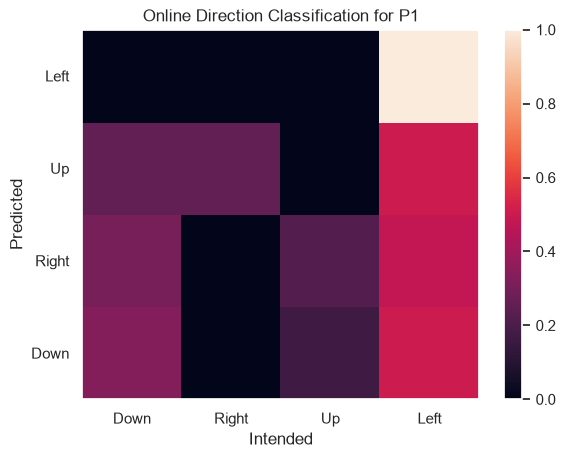

In [11]:
conf =data['confusion_matrix']
conf = np.transpose(np.transpose(conf) /np.sum(conf, axis=1))
conf = np.fliplr(conf)
plt.pcolor(conf)
plt.colorbar()
plt.title("Online Direction Classification for P1")
plt.xlabel("Intended")
plt.ylabel("Predicted")

plt.xticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left']  )
plt.yticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left'] )

# NSR004003 (P2)

In [12]:
file_path = os.path.join(DATA_ROOT, "NSR004003","Inference block_FIH0050blue_loc4_9_1744228833127_250409_160033")

with open(os.path.join(file_path, 'inference_stats.json')) as json_file:
    data = json.load(json_file)

In [13]:
print(f"Successful Trials {data['success']} of {data['total']}")

correct = np.zeros(4)
total = np.zeros(4)

for x,y in zip(data['labels'], data['predictions']):
    total[x] += 1
    if (x == y):
        correct[x] += 1

# weighted accuracy
p2_net_accuracy = np.sum(correct / total) / len(total)
print(f"Class Weighted Accuracy: {p2_net_accuracy}")

Successful Trials 21 of 34
Class Weighted Accuracy: 0.6833333333333333


[[2, 2, 0, 1], [4, 5, 0, 6], [0, 0, 4, 0], [0, 0, 0, 10]]


([<matplotlib.axis.YTick at 0x1ca916cb470>,
 [Text(0, 0.5, 'Down'),
  Text(0, 1.5, 'Right'),
  Text(0, 2.5, 'Up'),
  Text(0, 3.5, 'Left')])

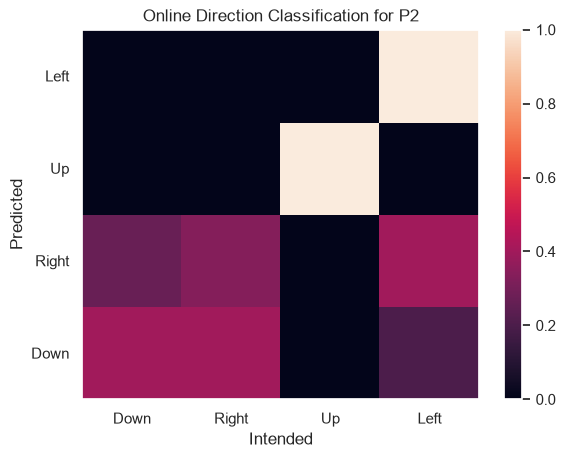

In [14]:
conf =data['confusion_matrix']
print(conf)
conf = np.transpose(np.transpose(conf) /np.sum(conf, axis=1))
#conf = np.fliplr(conf)

plt.pcolor(conf)
plt.colorbar()
plt.title("Online Direction Classification for P2")
plt.xlabel("Intended")
plt.ylabel("Predicted")
plt.xticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left']  )
plt.yticks([0.5, 1.5, 2.5, 3.5], labels =['Down', 'Right', 'Up', 'Left'] )

# NSR004004 (P3)

In [15]:
subject_root = os.path.join(DATA_ROOT, "NSR004004")

trial = "center-out-easy-inference_FIH0068__2_1753288323373_250723_163203"
#trial = "center-out-easy-block2_FIH0068__1_1753287064855_250723_161104"

with open( os.path.join(subject_root, trial, 'task_ui_events.jsonl'), 'r') as json_file:
    json_list = list(json_file)


cursor_x = []
cursor_y = []
cursor_times = []
completion_times = []
start_times = []
timeout_times = []
for json_item in json_list:
    result = json.loads(json_item)
    if('type' in result.keys()):
        if (result['type'] == 'event'):
            if(result['data']['type'] == 'movement'):
                cursor_x.append(result['data']['extra']['x'])
                cursor_y.append(result['data']['extra']['y'])
                cursor_times.append(result['microsecond'])
            elif(result['data']['type'] == 'targets_complete'):
                completion_times.append(result['microsecond'])
            elif(result['data']['type'] == 'target_initialized'):
                start_times.append(result['microsecond'])
            elif(result['data']['type'] == 'timeout'):
                timeout_times.append(result['microsecond'])

t0 = cursor_times[0]
cursor_times = np.asarray(cursor_times)

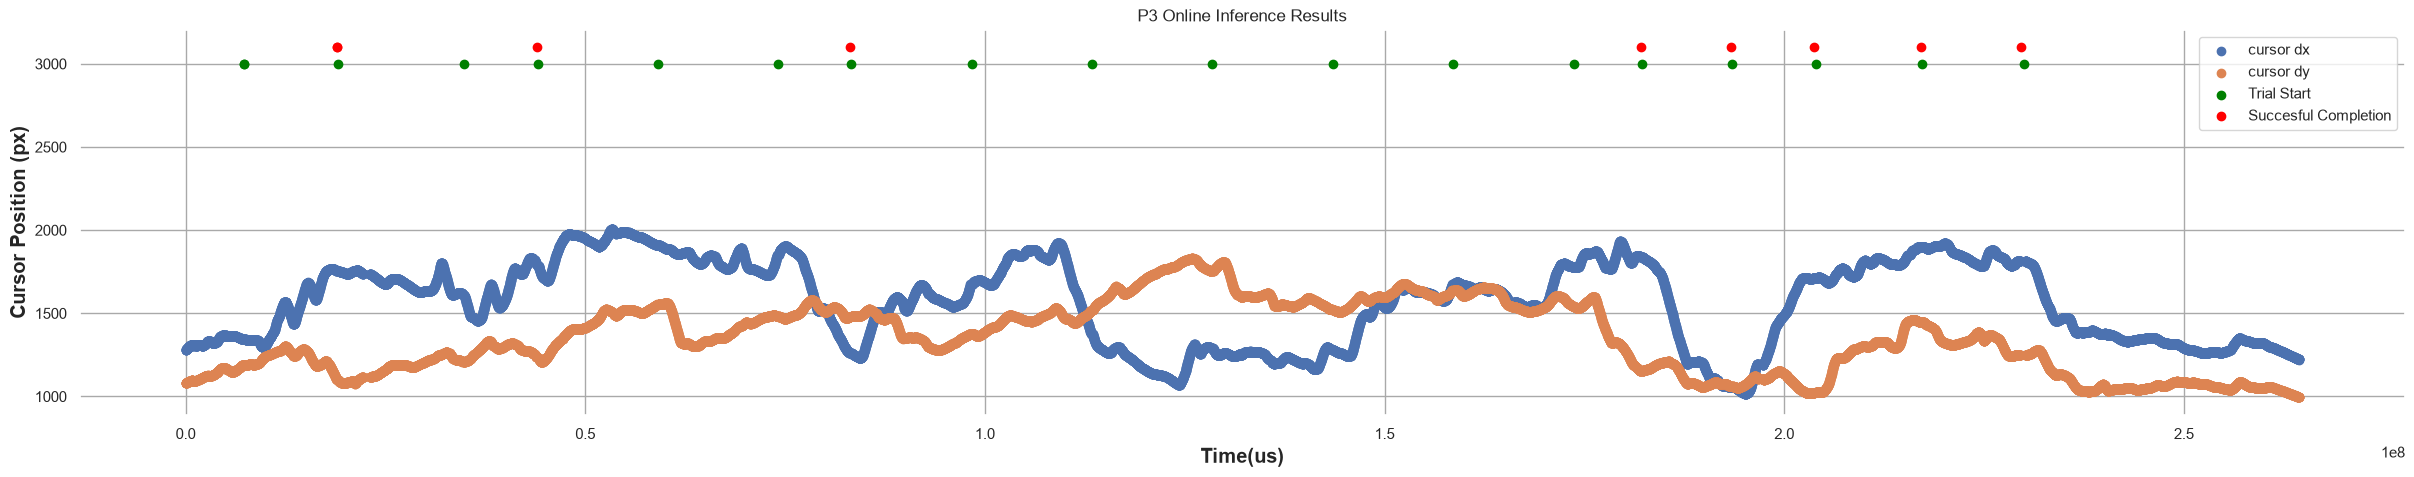

In [16]:
# Manually Check 
fig,ax = plt.subplots(1,1,figsize=(30,5))
plt.scatter((cursor_times-t0), cursor_x, label="cursor dx")
plt.scatter((cursor_times-t0), cursor_y, label="cursor dy")

s5_fs = 100
for point in start_times:
    plt.scatter([(point-t0)], [3000], color='green')
for point in completion_times:
    plt.scatter([(point-t0)], [3100], color='red')

for point in start_times[0:1]:
    plt.scatter([(point-t0)], [3000], color='green', label = "Trial Start" )
for point in completion_times[0:1]:
    plt.scatter([(point-t0)], [3100], color='red', label = "Succesful Completion")

ax.set_xlabel("Time(us)",weight="bold", size='large')
ax.set_ylabel('Cursor Position (px)',weight="bold", size='large')
plt.title("P3 Online Inference Results")
plt.legend()

In [17]:
# Computational Accuracy
cursor_x = np.asarray(cursor_x)
dist_thresh = 100
num_restarts = sum(  (np.abs(cursor_x[1:] - cursor_x[:-1]) > 100) )
 
p3_net_accuracy = len(completion_times)/(len(start_times)-1 + num_restarts)

print(f'total time (s): {(cursor_times[-1]-t0)/1000000}')
print(f'total success: {len(completion_times)}')
print(f'Success per minute: { len(completion_times) / ( (cursor_times[-1]-t0)/(1000000*60 ) ) }')
print(f"P3 Online Accuracy {p3_net_accuracy}")

total time (s): 264.43764
total success: 8
Success per minute: 1.8151727567981621
P3 Online Accuracy 0.47058823529411764


In [18]:
sstart_times = [start_times[0],start_times[2],start_times[5], start_times[12], start_times[13], start_times[14], start_times[15],start_times[16]]
time_elapsed = 1/1000000 * (np.asarray(completion_times) - np.asarray(sstart_times))
print(time_elapsed) 
print(np.median(time_elapsed), np.std(time_elapsed))

[11.621694  9.144546  8.972878  8.364494 11.133602 10.281583 13.181995
 12.325456]
10.7075925 1.6136463600816475


Text(0, 0.5, 'Y')

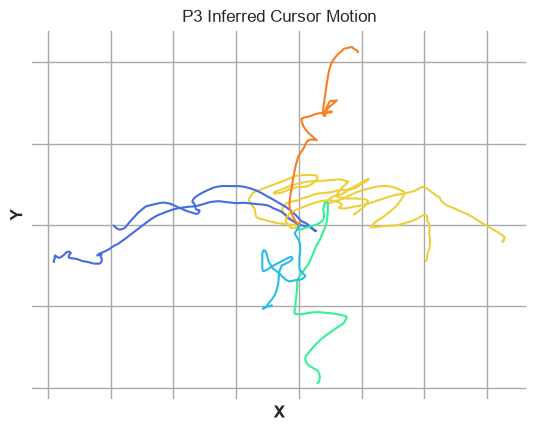

In [19]:
cursor_times = np.asarray(cursor_times)
cursor_x = np.asarray(cursor_x)
cursor_y = np.asarray(cursor_y)

## really this can be combined with the previous one 
for trial in range(len(sstart_times)):
    
    sidx = np.where(cursor_times < sstart_times[trial])[0][-1]
    eidx = np.where(cursor_times > completion_times[trial])[0][0]
    x = cursor_x[sidx:eidx] - cursor_x[sidx]
    y = cursor_y[sidx:eidx]- cursor_y[sidx]

    angle = 180/np.pi* np.atan2(  y[-1] - y[0], x[-1] - x[0] ) 
        
    angle_class = int( np.rint(angle / 45) + 4)
    
    if angle_class == 8:
        angle_class = 0
        
    plt.plot(x,y, color=color_list[angle_class] )

plt.title("P3 Inferred Cursor Motion")
plt.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False) # labels along the bottom edge are off
plt.tick_params(
    axis='y',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    left=False,        # ticks along the bottom edge are off
    right=False,        # ticks along the top edge are off
    labelleft=False) # labels along the bottom edge are off
plt.xlabel("X", weight="bold")
plt.ylabel("Y", weight="bold")

# NSR004005 (P4)

In [20]:
subject_root = "D:\\Becca\\Data\\PN\\NSR004005\\"
trial_list = []
trial_list.append("infer-veasy-hover_FIH0093_webgrid_1_1765991935483_251217_171855" )
trial_list.append("infer-veasy-hover_FIH0093_webgrid_2_1765992257513_251217_172417")

#filename = os.path.join(subject_root, trial, trial, "continuous",
#                        "CursorJoystickCRNNImplementation.GroundTruth","continuous.npy")

#inf_filename = os.path.join(subject_root, trial, trial, "continuous",
#                        "CursorJoystickCRNNImplementation.Postprocessed","continuous.npy")

fs = 200
#p4_ground_truth = np.load(filename)
#p4_infer = np.load(inf_filename)

In [21]:
cursor_x = []
cursor_y = []
cursor_times = []
completion_times = []
start_times = []
timeout_times = []
target_list = []
start_pos = []
for trial in trial_list:
    with open( os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl'), 'r') as json_file:
        json_list = list(json_file)
    s5_fs = 10

    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'movement'):
                    cursor_x.append(result['data']['cursor_position']['x'])
                    cursor_y.append(result['data']['cursor_position']['y'])
                    cursor_times.append(result['microsecond']/1000000)
                elif(result['data']['type'] == 'targets_complete'):
                    completion_times.append(result['microsecond']/1000000)
                elif(result['data']['type'] == 'target_initialized'):
                    start_times.append(result['microsecond']/1000000)
                    target_list.append([result["data"]["extra"]["coordinate_location"]["x"],result["data"]["extra"]["coordinate_location"]["y"]] )
                    start_pos.append([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]])
                elif(result['data']['type'] == 'timeout'):
                    timeout_times.append(result['microsecond']/1000000)
t0 = cursor_times[0]
print('---------')
print(t0)

---------
2231.6369


total time (s): 0.0006252449470000002
total success: 77
total trials: 78,7
Success per minute: 7.3891040977896925
Success Rate 0.9058823529411765


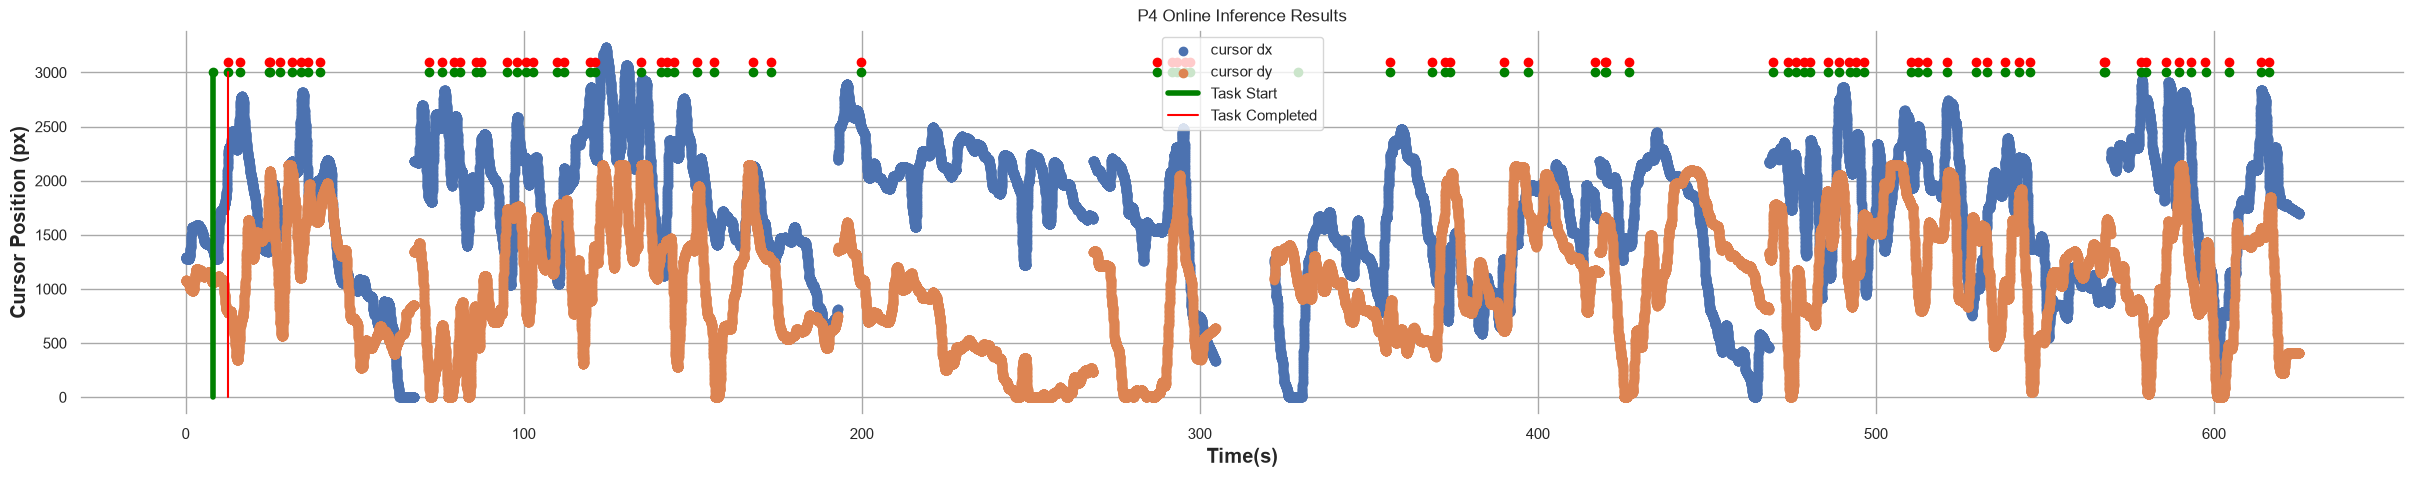

In [22]:
cursor_times = np.asarray(cursor_times)
cursor_x = np.asarray(cursor_x)

fig,ax = plt.subplots(1,1,figsize=(30,5))
plt.scatter((cursor_times-t0), cursor_x, label="cursor dx")
plt.scatter((cursor_times-t0), cursor_y, label="cursor dy")

s5_fs = 100
fs = 100000000
for point in start_times:
    plt.scatter([(point-t0)], [3000], color='green')
for point in completion_times:
    plt.scatter([(point-t0)], [3100], color='red')

#plt.scatter([.67*fs], [3000], color='green')
#plt.scatter([1.92*fs], [3000], color='green')
#plt.scatter([2.69*fs], [3000], color='green')

for point in start_times[0:1]:
    plt.plot([(point-t0)]*2, [0,3000], color='green', linewidth="4", label="Task Start")
for point in completion_times[0:1]:
    plt.plot([(point-t0)]*2, [0,3000], color='red', label="Task Completed")

ax.set_xlabel("Time(s)",weight="bold", size='large')
ax.set_ylabel('Cursor Position (px)',weight="bold", size='large')
plt.title("P4 Online Inference Results")
plt.legend()



dist_thresh = 100
num_restarts = sum(  (np.abs(cursor_x[1:] - cursor_x[:-1]) > 100) )
 
p4_net_success = (len(completion_times)) / (len(start_times) -1 + num_restarts )

print(f'total time (s): {(cursor_times[-1]-t0)/1000000}')
print(f'total success: {len(completion_times)}')
print(f'total trials: {len(start_times)-1},{+num_restarts}')
print(f'Success per minute: { len(completion_times) / ( (cursor_times[-1]-t0)/(60 ) ) }')
print(f'Success Rate {p4_net_success}')


# NSR102005 (P5)

In [23]:
session_root = "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\"
trial_list = ["webgrid-easy-random_FIH0117_infer_1_1767105022887_251230_143022", "webgrid-easy-random_FIH0117_infer_1_1767105453895_251230_143733"]

cursor_x = []
cursor_y = []
cursor_times = []
completion_times = []
start_times = []
timeout_times = []
target_list = []
start_pos = []
t0_list = []

for trial in trial_list:
    with open( os.path.join(session_root, trial,'task_ui_events.jsonl'), 'r') as json_file:
        json_list = list(json_file)
        file_t0 = True
        for json_item in json_list:
            result = json.loads(json_item)
            if('type' in result.keys()):
                if (result['type'] == 'event'):
                    if(result['data']['type'] == 'movement'):
                        cursor_x.append(result['data']['cursor_position']['x'])
                        cursor_y.append(result['data']['cursor_position']['y'])
                        cursor_times.append(result['microsecond'])

                        if(file_t0):
                            t0_list.append(result['microsecond'])
                            file_t0 = False
                    elif(result['data']['type'] == 'targets_complete'):
                        completion_times.append(result['microsecond'])
                    elif(result['data']['type'] == 'target_initialized'):
                        start_times.append(result['microsecond'])
                    elif(result['data']['type'] == 'timeout'):
                        timeout_times.append(result['microsecond'])
        

P5 Online Succes rate 0.55


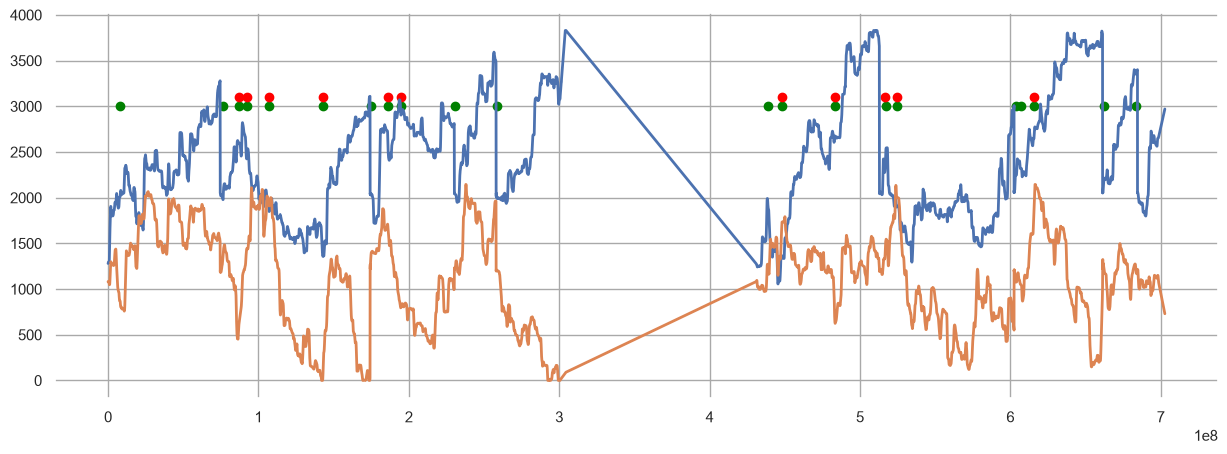

In [24]:
fig,ax = plt.subplots(1,1,figsize=(15,5))

cursor_times = np.asarray(cursor_times)
start_times = np.asarray(start_times)
completion_times = np.asarray(completion_times)
plt.plot(cursor_times - cursor_times[0], cursor_x, label="X", linewidth=2)# - np.mean(cursor_x))
plt.plot(cursor_times- cursor_times[0], cursor_y, label="Y", linewidth=2 )# - np.mean(cursor_y))
plt.scatter(start_times- cursor_times[0], 3000*np.ones(len(start_times)), color='green', label = "Task Start")
plt.scatter(completion_times- cursor_times[0], 3100*np.ones(len(completion_times)), color='red', label = "Task Complete")

#print(f'total time (s): {( cursor_times[-1]-cursor_times[0]+cursor_times2[-1]-cursor_times2[0]    )/1000000}')
#print(f'total success: {len(completion_times)}')
#print(f'Success per minute: { len(completion_times) / ( ( cursor_times[-1]-cursor_times[0]+cursor_times2[-1]-cursor_times2[0]    )/(1000000*60 ) ) }')

p5_net_success = len(completion_times) / (len(start_times)-1)
print(f'P5 Online Succes rate {p5_net_success}')

# P5 Session 8

In [25]:
session_root = "D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\"
trial_list = []
trial_list.append("webgrid-easy_FIH0117_infer_1_1767206977752_251231_184937")

cursor_x = []
cursor_y = []
cursor_times = []
completion_times = []
start_times = []
timeout_times = []
target_list = []
start_pos = []
t0_list = []

for trial in trial_list:
    with open( os.path.join(session_root, trial,'task_ui_events.jsonl'), 'r') as json_file:
        json_list = list(json_file)
        file_t0 = True
        for json_item in json_list:
            result = json.loads(json_item)
            if('type' in result.keys()):
                if (result['type'] == 'event'):
                    if(result['data']['type'] == 'movement'):
                        cursor_x.append(result['data']['cursor_position']['x'])
                        cursor_y.append(result['data']['cursor_position']['y'])
                        cursor_times.append(result['microsecond'])

                        if(file_t0):
                            t0_list.append(result['microsecond'])
                            file_t0 = False
                    elif(result['data']['type'] == 'targets_complete'):
                        completion_times.append(result['microsecond'])
                    elif(result['data']['type'] == 'target_initialized'):
                        start_times.append(result['microsecond'])
                    elif(result['data']['type'] == 'timeout'):
                        timeout_times.append(result['microsecond'])

In [26]:
p5b_net_success = len(completion_times) / (len(start_times)-1)
print(f'P5b Online Succes rate {p5b_net_success}')

P5b Online Succes rate 1.0


# Figure 2 abc

In [27]:
def s5_load_data(json_filename, tasktype = "INFER"):
    
    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

    s5_fs = 10
    t0 = None
    state = "REST"
    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'target_initialized'):
                    match state:
                        case "TRIAL":
                            status_list.append("FAIL")
                            time_list.append(-1)
                            subject_list.append("P4")
                            end_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            type_list.append(tasktype)
                            
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            target_list.append(np.asarray([result["data"]["extra"]["coordinate_location"]["x"],result["data"]["extra"]["coordinate_location"]["y"]] ) )

                        case "REST":
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(np.asarray([result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            target_list.append(np.asarray([result["data"]["extra"]["coordinate_location"]["x"],result["data"]["extra"]["coordinate_location"]["y"]]) )


                        case _ :
                            raise ValueError(f"INVALID STATE")

                
                elif(result['data']['type'] == 'targets_complete'):
                    match state:
                        case "REST":
                            raise ValueError(f"SHOULD NOT BE IN REST")
                        case "TRIAL":
                            state = "REST"
                            dt = (result['microsecond'] - t0)/1000000
                            status_list.append("SUCCESS")
                            time_list.append(dt)
                            subject_list.append("P4")
                            end_pos_list.append(np.asarray( [result["data"]["cursor_position"]["x"],result["data"]["cursor_position"]["y"]]) )
                            type_list.append(tasktype)
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [28]:
def s4_load_data(json_filename, tasktype = "INFER"):
    
    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

    s5_fs = 10
    t0 = None
    state = "REST"
    for json_item in json_list:
        result = json.loads(json_item)
        if('type' in result.keys()):
            if (result['type'] == 'event'):
                if(result['data']['type'] == 'target_initialized'):
                    match state:
                        case "TRIAL":
                            status_list.append("FAIL")
                            time_list.append(-1)
                            subject_list.append("P3")
                            end_pos_list.append(None )
                            type_list.append(tasktype)
                            
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(None )
                            target_list.append(None )

                        case "REST":
                            t0 = result['microsecond']
                            state = "TRIAL"
                            start_pos_list.append(None )
                            target_list.append(None )

                        case _ :
                            raise ValueError(f"INVALID STATE")

                
                elif(result['data']['type'] == 'targets_complete'):
                    match state:
                        case "REST":
                            raise ValueError(f"SHOULD NOT BE IN REST")
                        case "TRIAL":
                            state = "REST"
                            dt = (result['microsecond'] - t0)/1000000
                            status_list.append("SUCCESS")
                            time_list.append(dt)
                            subject_list.append("P3")
                            end_pos_list.append(None )
                            type_list.append(tasktype)
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [29]:
def nsr1002005_pull_data_from_file(json_filename, trial_type = "INFER", NAME = "P5", FAILURE_TIME_THRSH = 60):

    subject_list = []
    time_list = []
    status_list = []
    target_list = []
    start_pos_list = []
    end_pos_list = []
    type_list = []
    

    with open( json_filename, 'r') as json_file:
        json_list = list(json_file)

        t0 = None
        state = "REST"

        #try:
        for json_item in json_list:
            result = json.loads(json_item)
            if('type' in result.keys()):
                if (result['type'] == 'event'):
                    if(result['data']['type'] == 'target_initialized'):
                        match state:
                            case "REST":
                                t0 = result['microsecond']
                                state = "TRIAL"

                                target_list.append(None)
                                start_pos_list.append(None)
                            case "TRIAL":
                                status_list.append("FAIL")
                                time_list.append(-1)
                                subject_list.append(NAME)
                                type_list.append(trial_type)
                                end_pos_list.append(None)


                                t0 = result['microsecond']
                                target_list.append(None)
                                start_pos_list.append(None)

                            case _: 
                                raise ValueError(f"The state {state} is not valid.")

                    elif(result['data']['type'] == 'targets_complete'):
                        match state:
                            case "REST":
                                raise ValueError(f"SHOULD NOT BE IN REST")
                            case "TRIAL":
                                dt = (result['microsecond'] - t0)/1000000
                                
                                status_list.append("SUCCESS")
                                time_list.append(dt)
                                subject_list.append(NAME)
                                type_list.append(trial_type)
                                end_pos_list.append(None)

                                t0 = None
                                state = "REST"
                            case _: 
                                raise ValueError(f"The state {state} is not valid.")
    if (len(target_list) == len(time_list) ):
        target_list.append(None)
        start_pos_list.append(None)
    df = pd.DataFrame({
                        'Subject': subject_list,
                        'time': time_list,
                        'status': status_list,
                        'Target': target_list[:-1],
                        'Start': start_pos_list[:-1],
                        'End': end_pos_list,
                        'Block Type': type_list        
                        })
    
    return df

In [30]:
# Put all data into dataframe
df_list = []

subject_root = "D:\\Becca\\Data\\PN\\NSR004005\\"
trial = "infer-veasy-hover_FIH0093_webgrid_1_1765991935483_251217_171855"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "INFER")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3) &(p4_df["time"] > 0.2) ]
df_list.append(p4_df)

subject_root = "D:\\Becca\\Data\\PN\\NSR004005\\"
trial = "infer-veasy-hover_FIH0093_webgrid_2_1765992257513_251217_172417"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "INFER")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3) &(p4_df["time"] > 0.2) ]
df_list.append(p4_df)


trial = "train-veasy-hover_FIH0093_webgrid_2_1765990632034_251217_165712"
P4_file = os.path.join(subject_root, trial, trial, 'task_ui_events.jsonl')
p4_df = s5_load_data(P4_file, "TRAIN")
p4_df = p4_df[p4_df["status"] == "SUCCESS"]
p4_df = p4_df[(np.abs(zscore(p4_df["time"])) < 3)]
df_list.append(p4_df)


subject_root = "D:\\Becca\\Data\\PN\\NSR004004\\"
trial = "center-out-easy-inference_FIH0068__2_1753288323373_250723_163203"
P3_file = os.path.join(subject_root, trial, 'task_ui_events.jsonl')
p3_df = s4_load_data(P3_file, "INFER")
p3_df = p3_df[p3_df["status"] == "SUCCESS"]
p3_df = p3_df[(np.abs(zscore(p3_df["time"])) < 3)]
df_list.append(p3_df)

trial = "center-out-easy-block1_FIH0068__1_1753286802143_250723_160642"
P3_file = os.path.join(subject_root, trial, 'task_ui_events.jsonl')
p3_df = s4_load_data(P3_file, "TRAIN")
p3_df = p3_df[(np.abs(zscore(p3_df["time"])) < 3)]
df_list.append(p3_df)

p5_trial = "D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-easy-random_FIH0117_infer_1_1767105022887_251230_143022\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "INFER", "P5a")
p5_df = p5_df[p5_df["status"] == "SUCCESS"]
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session2\\29-DEC-2025\\webgrid-medium-random_FIH0117_train_1_1767103993233_251230_141313\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "TRAIN", "P5a")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-easy_FIH0117_infer_1_1767206977752_251231_184937\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "INFER", "P5b")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)

p5_trial ="D:\\Becca\\Data\\PN\\NSR-102-005\\Session8\\29-DEC-2025\\webgrid-hard_FIH0117_train_1_1767203809930_251231_175649\\"
p5_file = os.path.join(p5_trial,'task_ui_events.jsonl')
p5_df = nsr1002005_pull_data_from_file(p5_file, "TRAIN", "P5b")
p5_df = p5_df[(np.abs(zscore(p5_df["time"])) < 3)]
df_list.append(p5_df)



all_df = pd.concat(df_list)

C:\Users\Becca\AppData\Local\Temp\ipykernel_33504\3428986952.py:73: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  vp1 = sns.violinplot(data=all_df[all_df['Block Type'] == "TRAIN"],
C:\Users\Becca\AppData\Local\Temp\ipykernel_33504\3428986952.py:110: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  vp2 = sns.violinplot(data=all_df[all_df['Block Type'] == "INFER" ],


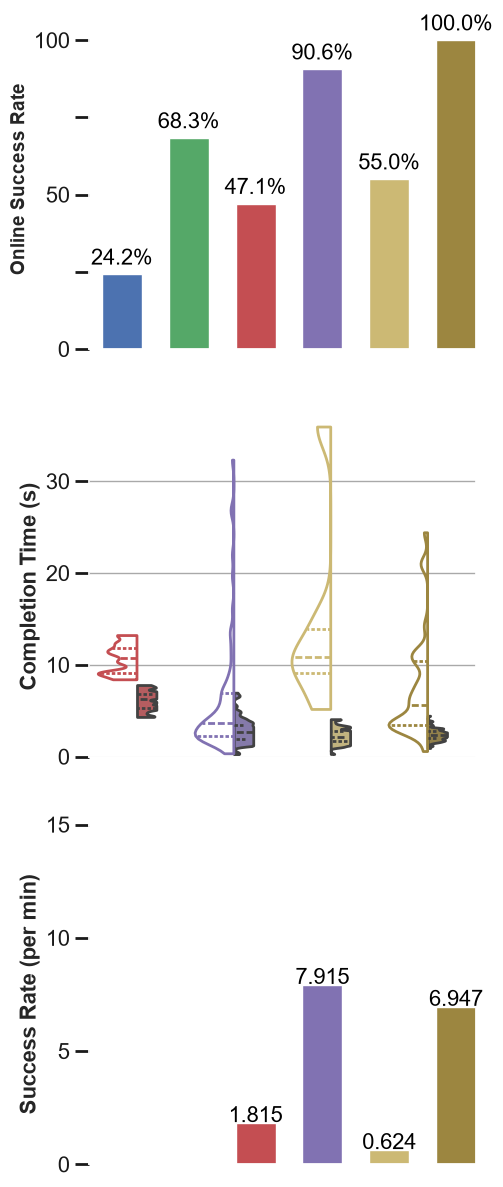

In [31]:
sns.set(rc={
    "axes.facecolor": "#FFFFFF",  # change this to any color you want
    "grid.color": "#A9A9A9", 
})

fig,ax = plt.subplots(3,1, figsize = (5,15),frameon=False)


participants = np.asarray([1,2,3,4,5,6] )
success_rate = [p1_net_accuracy,
                p2_net_accuracy,
                p3_net_accuracy,
                p4_net_success,
                p5_net_success,
                p5b_net_success,
                ]

color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974','#9C8640']
#---------------------------------------------------------------------
# AX0: Success rate bar
ax0_bars = ax[0].bar(participants,success_rate,color=color_set,width=0.6 )


for bar in ax0_bars:
    height = bar.get_height()
    ax[0].text(
        bar.get_x() + bar.get_width() / 2,
        height+0.05,                  # inside the bar
        f'{np.round(100*height,1)}%',
        ha='center',
        va='center',
        color='black',
        fontsize=16
    )

ax[0].set_xticks([1,2,3,4,5] )
#ax[0].set_xticklabels(["P1", "P2","P3","P4","P5"], weight="bold")
ax[0].set_xticks([])
ax[0].set_ylim(0,1.1)
ax[0].set_yticks([0,1])
ax[0].set_yticklabels(["0","1"])
ax[0].set_ylabel("Online Success Rate",fontsize=14, weight="bold")
ax[0].set_xlim([0.5,6.3] )


legend0_elements = [
    Patch(facecolor=color_set[0], edgecolor=color_set[0], label='P1', linewidth=5),
    Patch(facecolor=color_set[1], edgecolor=color_set[1], label='P2', linewidth=5),
    Patch(facecolor=color_set[2], edgecolor=color_set[2], label='P3', linewidth=5),
    Patch(facecolor=color_set[3], edgecolor=color_set[3], label='P4', linewidth=5),
    Patch(facecolor=color_set[4], edgecolor=color_set[4], label='P5 (First)', linewidth=5),
    Patch(facecolor=color_set[5], edgecolor=color_set[5], label='P5 (Best)', linewidth=5),

]
ax[0].grid(False)
#ax[0].legend(handles=legend0_elements, fontsize=16, frameon=False, ncol=6)


ax[0].tick_params(axis='y',
                reset=True,
                labelsize=16,
                length=10,
                width=2,
                colors='k',
                right=False )
ax[0].set_yticks([0,0.25,0.5, 0.75, 1])
ax[0].set_yticklabels(["0","", "50", "", "100"])
ax[0].grid(False)
#ax[1].set_xticks([1,2,3,4,5,6] )

#---------------------------------------------------------------------
# AX1: Completion timing, violin
vp1 = sns.violinplot(data=all_df[all_df['Block Type'] == "TRAIN"],
            y="time", 
            order=["P3", "P4", "P5a", "P5b"], 
            x="Subject", 
            hue="Subject",
            palette={
            'P3': color_set[2],
            'P4': color_set[3],
            "P5a": color_set[4],
            "P5b": color_set[5],
            },
            split=False, 
            inner="quart", 
            cut= 0, 
            bw_adjust = 0.3, 
            fill=True, 
            ax=ax[1], 
            linewidth=2, 
            scale='width')


for collection in vp1.collections:
    if isinstance(collection, plt.matplotlib.collections.PolyCollection):
        path = collection.get_paths()[0]
        vertices = path.vertices

        # Center of the violin in x
        center = (vertices[:, 0].min() + vertices[:, 0].max()) / 2

        # Move points on the left side to the center
        vertices[:, 0] = np.maximum(vertices[:, 0], center)


for i, obj in enumerate(vp1.lines):
    center = np.mean(obj.get_xdata())
    obj.set_xdata([center, obj.get_xdata()[1]])

vp2 = sns.violinplot(data=all_df[all_df['Block Type'] == "INFER" ],
            y="time", 
            order=["P3", "P4", "P5a", "P5b"], 
            x="Subject", 
            hue="Subject",
            palette={
            'P3': color_set[2],
            'P4': color_set[3],
            "P5a": color_set[4],
            "P5b": color_set[5],
            },
            split=False, 
            inner="quart", 
            cut= 0, 
            bw_adjust = 0.3, 
            fill=False, 
            ax=ax[1], 
            linewidth=2, 
            scale='width')

for i, obj in enumerate(vp2.lines):
    center = np.mean(obj.get_xdata())
    obj.set_xdata([center, obj.get_xdata()[0]])

for collection in vp2.collections:
    if isinstance(collection, plt.matplotlib.collections.PolyCollection):
        path = collection.get_paths()[0]
        vertices = path.vertices

        # Center of the violin in x
        center = (vertices[:, 0].min() + vertices[:, 0].max()) / 2

        # Move points on the right side to the center
        vertices[:, 0] = np.minimum(vertices[:, 0], center)

ax[1].set_ylabel("Completion Time (s)",fontsize=16, weight="bold")
ax[1].set_xticks([])
ax[1].set_xlabel("")

legend_elements = [
    Patch(facecolor='black', edgecolor='black', label='TRAIN', linewidth=5),
    Patch(facecolor='none', edgecolor='black', label='INFER', linewidth=5)
]
ax[1].tick_params(axis='y',
                    reset=True,
                    labelsize=16,
                    length=10,
                    width=2,
                    colors='k',
                    right=False )
ax[1].set_ylim([0,37])
#ax[1].legend(handles=legend_elements, fontsize=16, frameon=False)


#---------------------------------------------------------------------
# AX2: Success per minute
#-----------------------------
spm = np.asarray([#0, # P1 
                  #0, # P2
                  1.815, # P3
                  7.915, # P4
                  0.624, # P5 first
                  6.947, # P5 'best'
                  ])
tspm = np.asarray([#0, # P1 
                  #0, # P2
                  6.498, # P3
                  18.036, # P4
                  25.658, # P5 first
                  23.108, # P5 'best'
                  ])

Wp = np.asarray([4.52, 3.14, 12.12, 5.03])
#ax2_bars = ax[2].bar(participants[2:],Wp,color=color_set[2:],width=0.6)
ax2_bars = ax[2].bar(participants[2:],spm,color=color_set[2:],width=0.6)

ax[2].set_xlim(0.5, 6.3)

for bar in ax2_bars:
    height = bar.get_height()
    ax[2].text(
        bar.get_x() + bar.get_width() / 2,
        height+0.3,                 # inside the bar
        f'{np.round(height,3)}',
        ha='center',
        va='center',
        color='black',
        fontsize=16
    )
ax[2].grid(False)
ax[2].set_xticks([])
ax[2].set_yticks([0,5,10,15])
ax[2].set_ylabel("Success Rate (per min)",fontsize=16, weight="bold")
ax[2].tick_params(axis='y',
                    reset=True,
                    labelsize=16,
                    length=10,
                    width=2,
                    colors='k',
                    right=False )
ax[2].grid(False)

In [39]:
from scipy import stats
for subject in ["P3", "P4", "P5a", "P5b"]:
    train_timing = all_df[ (all_df['Block Type'] == "TRAIN") & (all_df["Subject"] == subject) ]["time"].to_numpy()
    infer_timing = all_df[ (all_df['Block Type'] == "INFER") & (all_df["Subject"] == subject) ]["time"].to_numpy()

    w, p = stats.brunnermunzel(train_timing, infer_timing, alternative='two-sided')
    print(subject, w, p)

P3 inf nan
P4 3.890672693202697 0.00016412678355150385
P5a inf nan
P5b 11.022995015956095 1.944234130766223e-13


D:\Becca\Layer7\.venv\Lib\site-packages\scipy\stats\_stats_py.py:8901: RuntimeWarning: divide by zero encountered in scalar divide
  wbfn /= (nx + ny) * xp.sqrt(nx * Sx + ny * Sy)
D:\Becca\Layer7\.venv\Lib\site-packages\scipy\stats\_stats_py.py:8907: RuntimeWarning: invalid value encountered in scalar divide
  df = df_numer / df_denom
D:\Becca\Layer7\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: p-value cannot be estimated with `distribution='t' because degrees of freedom parameter is undefined (0/0). Try using `distribution='normal'
  res = hypotest_fun_out(*samples, **kwds)
D:\Becca\Layer7\.venv\Lib\site-packages\scipy\stats\_stats_py.py:8901: RuntimeWarning: divide by zero encountered in scalar divide
  wbfn /= (nx + ny) * xp.sqrt(nx * Sx + ny * Sy)
D:\Becca\Layer7\.venv\Lib\site-packages\scipy\stats\_stats_py.py:8907: RuntimeWarning: invalid value encountered in scalar divide
  df = df_numer / df_denom
D:\Becca\Layer7\.venv\Lib\site-packages\scipy\sta

# Figure 2f 

Text(0.5, 1.0, 'P4 Online Inference')

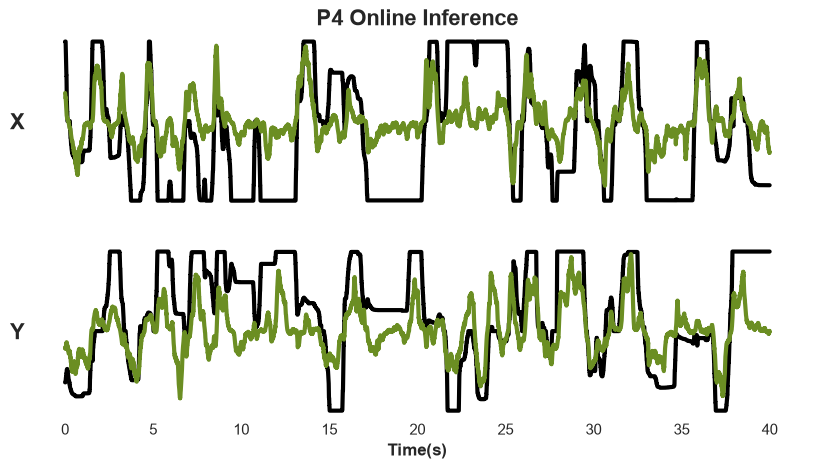

In [43]:
fs = 200


fig,ax = plt.subplots(2,1,figsize=(10,5))
t1 = 7000
t2= t1+40*fs

ts = np.arange(0,(t2-t1)/fs, 1/fs)
ax[0].plot(ts,p4_ground_truth[t1:t2,0], linewidth=3,label="Joystick Position", color='black')
ax[0].plot(ts,p4_infer[t1:t2,0],label="Cursor Velocity", linewidth=3,color='olivedrab')
#ax[0].set_yticks([])
#ax[0].set_xticks([])

#ax[0].legend(loc = "lower left")
ax[0].set_xticklabels([])
ax[0].grid(False)
ax[0].set_facecolor('#ffffff')
ax[0].set_yticks([0])
ax[0].set_yticklabels(["X"], weight="bold", fontsize=16)
ax[0].set_frame_on(False)
ax[0].tick_params(axis='both', length=0)

ax[1].plot(ts,p4_ground_truth[t1:t2,1], label="Joystick Position", linewidth=3, color='black')
ax[1].plot(ts,p4_infer[t1:t2,1],label="Cursor Velocity", linewidth=3,color='olivedrab')
ax[1].set_yticks([])
ax[1].set_xlabel("Time(s)", weight="bold")
#ax[1].set_xticks(np.arange(0,80*fs+1,2000))
#ax[1].set_xticklabels([0,"",20,"",40,"",60,"",80], fontsize=14)
ax[1].grid(False)
ax[1].set_facecolor('#ffffff')
ax[1].set_yticks([0])
ax[1].set_yticklabels(["Y"], weight="bold",fontsize=16)
ax[1].set_frame_on(False)
ax[1].tick_params(axis='both', length=0)

#fig.supylabel("P4 Online Inference", weight="bold", fontsize=16)

ax[0].set_title("P4 Online Inference", weight="bold", fontsize=16)